In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


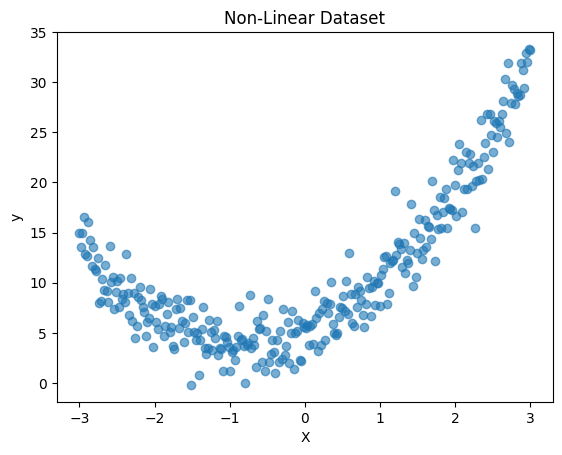

Training samples: 240
Testing samples: 60


In [9]:
np.random.seed(42)

X = np.linspace(-3, 3, 300).reshape(-1, 1)
y = 2 * X[:, 0]**2 + 3 * X[:, 0] + 5
y = y + np.random.normal(0, 2, size=len(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

plt.scatter(X, y, alpha=0.6)
plt.title("Non-Linear Dataset")
plt.xlabel("X")
plt.ylabel("y")
plt.show()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

In [10]:
models = {
    "Linear Regression": make_pipeline(
        StandardScaler(), LinearRegression()
    ),
    "Polynomial Degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(), LinearRegression()
    ),
    "Polynomial Degree 5": make_pipeline(
        PolynomialFeatures(degree=5, include_bias=False),
        StandardScaler(), LinearRegression()
    ),
    "Polynomial Degree 10": make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(), LinearRegression()
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test R2": r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                  Model  Train MSE  Test MSE  Test RMSE  Test R2
0     Linear Regression    32.9609   28.2274     5.3129   0.5111
1   Polynomial Degree 2     4.1375    2.6626     1.6317   0.9539
2   Polynomial Degree 5     4.1043    2.7230     1.6502   0.9528
3  Polynomial Degree 10     3.9789    2.8986     1.7025   0.9498


In [11]:
regularized_models = {
    "Ridge": make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Lasso": make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(),
        Lasso(alpha=0.1, max_iter=10000)
    )
}

for name, model in regularized_models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test R2": r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                  Model  Train MSE  Test MSE  Test RMSE  Test R2
0     Linear Regression    32.9609   28.2274     5.3129   0.5111
1   Polynomial Degree 2     4.1375    2.6626     1.6317   0.9539
2   Polynomial Degree 5     4.1043    2.7230     1.6502   0.9528
3  Polynomial Degree 10     3.9789    2.8986     1.7025   0.9498
4                 Ridge     4.0375    2.7141     1.6475   0.9530
5                 Lasso     4.0944    2.6369     1.6239   0.9543


In [12]:
regularized_models = {
    "Ridge": make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Lasso": make_pipeline(
        PolynomialFeatures(degree=10, include_bias=False),
        StandardScaler(),
        Lasso(alpha=0.1, max_iter=10000)
    )
}

for name, model in regularized_models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test R2": r2_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                  Model  Train MSE  Test MSE  Test RMSE  Test R2
0     Linear Regression    32.9609   28.2274     5.3129   0.5111
1   Polynomial Degree 2     4.1375    2.6626     1.6317   0.9539
2   Polynomial Degree 5     4.1043    2.7230     1.6502   0.9528
3  Polynomial Degree 10     3.9789    2.8986     1.7025   0.9498
4                 Ridge     4.0375    2.7141     1.6475   0.9530
5                 Lasso     4.0944    2.6369     1.6239   0.9543
6                 Ridge     4.0375    2.7141     1.6475   0.9530
7                 Lasso     4.0944    2.6369     1.6239   0.9543


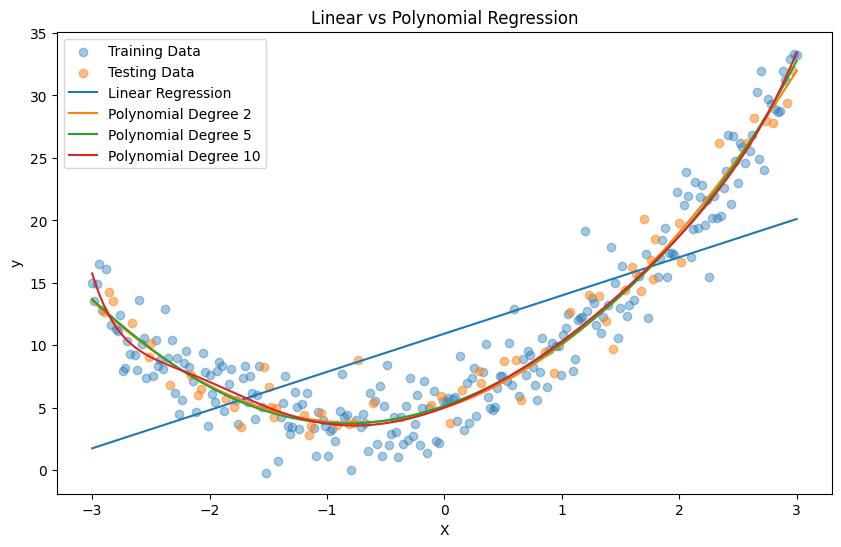

In [13]:
X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, alpha=0.4, label="Training Data")
plt.scatter(X_test, y_test, alpha=0.5, label="Testing Data")

for name, model in models.items():
    model.fit(X_train, y_train)
    plt.plot(X_plot, model.predict(X_plot), label=name)

plt.title("Linear vs Polynomial Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

In [14]:
results_df.to_csv("assignment2_results.csv", index=False)
print("Results saved successfully!")

Results saved successfully!
